In [ ]:
#Arslan Ahmed - DistilBERT

In [ ]:
import tensorflow as tf
from transformers import DistilBertTokenizer, TFDistilBertForSequenceClassification
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
import re
def load_data(file_path):
    return pd.read_csv(file_path, delimiter=';', header=None, names=['text', 'label'])

# Load datasets
train_data = load_data('/content/train.txt')
val_data = load_data('/content/val.txt')
test_data = load_data('/content/test.txt')

# Clean text and encode labels
def clean_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    return text

train_data['text'] = train_data['text'].apply(clean_text)
val_data['text'] = val_data['text'].apply(clean_text)
test_data['text'] = test_data['text'].apply(clean_text)

label_encoder = LabelEncoder()
train_data['label'] = label_encoder.fit_transform(train_data['label'])
val_data['label'] = label_encoder.transform(val_data['label'])
test_data['label'] = label_encoder.transform(test_data['label'])


In [ ]:
# Display the first 5 entries of the training data
print("Training Data Head:")
print(train_data.head())

# Similarly, you can display for validation and test datasets
print("\nValidation Data Head:")
print(val_data.head())

print("\nTest Data Head:")
print(test_data.head())


Training Data Head:
                                                text  label
0                            i didnt feel humiliated      4
1  i can go from feeling so hopeless to so damned...      4
2   im grabbing a minute to post i feel greedy wrong      0
3  i am ever feeling nostalgic about the fireplac...      3
4                               i am feeling grouchy      0

Validation Data Head:
                                                text  label
0  im feeling quite sad and sorry for myself but ...      4
1  i feel like i am still looking at a blank canv...      4
2                     i feel like a faithful servant      3
3                  i am just feeling cranky and blue      0
4  i can have for a treat or if i am feeling festive      2

Test Data Head:
                                                text  label
0  im feeling rather rotten so im not very ambiti...      4
1          im updating my blog because i feel shitty      4
2  i never make her separate from me bec

In [ ]:
# Summary of labels in the training data
print("\nLabel Summary in Training Data:")
print(train_data['label'].value_counts())

# If you need to display the summary for validation and test data as well
print("\nLabel Summary in Validation Data:")
print(val_data['label'].value_counts())

print("\nLabel Summary in Test Data:")
print(test_data['label'].value_counts())



Label Summary in Training Data:
label
2    5362
4    4666
0    2159
1    1937
3    1304
5     572
Name: count, dtype: int64

Label Summary in Validation Data:
label
2    704
4    550
0    275
1    212
3    178
5     81
Name: count, dtype: int64

Label Summary in Test Data:
label
2    695
4    581
0    275
1    224
3    159
5     66
Name: count, dtype: int64


In [ ]:
# Statistical summary of the labels
print("\nStatistical Summary of Labels in Training Data:")
print(train_data['label'].describe())

# If the text length is crucial, you might first want to calculate it
train_data['text_length'] = train_data['text'].apply(len)
print("\nStatistical Summary of Text Lengths in Training Data:")
print(train_data['text_length'].describe())



Statistical Summary of Labels in Training Data:
count    16000.000000
mean         2.381063
std          1.444121
min          0.000000
25%          1.000000
50%          2.000000
75%          4.000000
max          5.000000
Name: label, dtype: float64

Statistical Summary of Text Lengths in Training Data:
count    16000.000000
mean        96.845812
std         55.904953
min          7.000000
25%         53.000000
50%         86.000000
75%        129.000000
max        300.000000
Name: text_length, dtype: float64


In [ ]:
# Summary of labels in the training data
print("\nLabel Summary in Training Data:")
print(train_data['label'].value_counts())

# If you also want to see this for validation and test datasets
print("\nLabel Summary in Validation Data:")
print(val_data['label'].value_counts())
print("\nLabel Summary in Test Data:")
print(test_data['label'].value_counts())



Label Summary in Training Data:
label
2    5362
4    4666
0    2159
1    1937
3    1304
5     572
Name: count, dtype: int64

Label Summary in Validation Data:
label
2    704
4    550
0    275
1    212
3    178
5     81
Name: count, dtype: int64

Label Summary in Test Data:
label
2    695
4    581
0    275
1    224
3    159
5     66
Name: count, dtype: int64


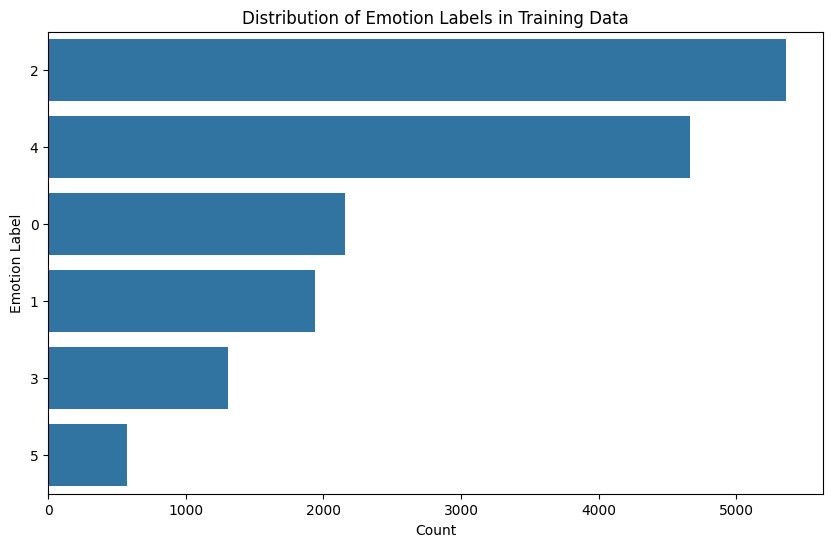

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting the distribution of labels
plt.figure(figsize=(10, 6))
sns.countplot(y='label', data=train_data, order=train_data['label'].value_counts().index)
plt.title('Distribution of Emotion Labels in Training Data')
plt.xlabel('Count')
plt.ylabel('Emotion Label')
plt.show()


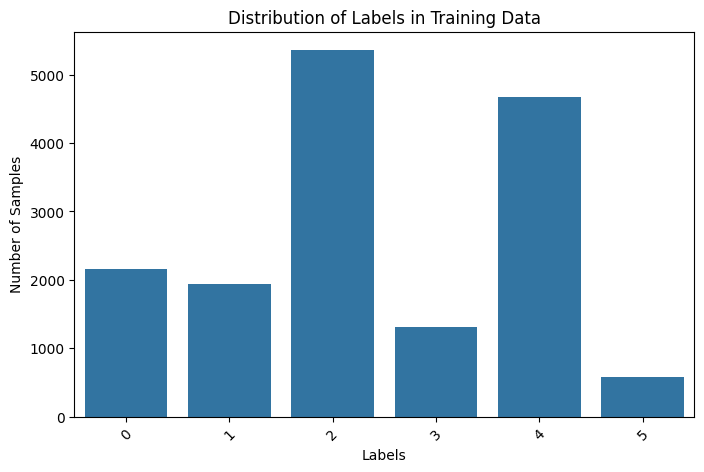

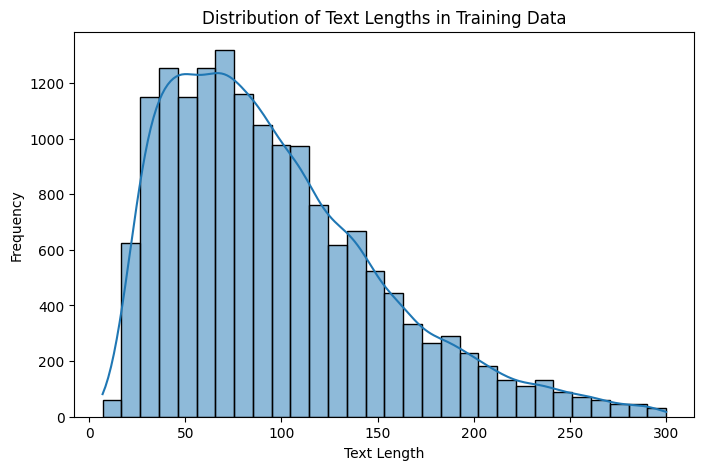

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of labels
plt.figure(figsize=(8, 5))
sns.countplot(x='label', data=train_data)
plt.title('Distribution of Labels in Training Data')
plt.xlabel('Labels')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.show()

# Visualize the length of texts
train_data['text_length'] = train_data['text'].apply(len)
plt.figure(figsize=(8, 5))
sns.histplot(train_data['text_length'], bins=30, kde=True)
plt.title('Distribution of Text Lengths in Training Data')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.show()


In [ ]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_and_encode(sentences, max_len=128):
    return tokenizer(sentences, padding=True, truncation=True, max_length=max_len, return_tensors="tf")

train_encodings = tokenize_and_encode(train_data['text'].tolist())
val_encodings = tokenize_and_encode(val_data['text'].tolist())
test_encodings = tokenize_and_encode(test_data['text'].tolist())


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

In [ ]:
model = TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=len(label_encoder.classes_))

# Compile the model
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

# Train the model
train_dataset = tf.data.Dataset.from_tensor_slices((dict(train_encodings), train_data['label'])).batch(32)
val_dataset = tf.data.Dataset.from_tensor_slices((dict(val_encodings), val_data['label'])).batch(32)

history = model.fit(train_dataset, epochs=5, validation_data=val_dataset)


Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFDistilBertForSequenceClassification: ['vocab_transform.weight', 'vocab_transform.bias', 'vocab_layer_norm.bias', 'vocab_layer_norm.weight', 'vocab_projector.bias']
- This IS expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFDistilBertForSequenceClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFDistilBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['pre_classifier.weight', 'pre_classifier.bias', 'classifier.weight', 'classifier.bias']
You should 

Epoch 1/5
500/500 [==============================] - 194s 287ms/step - loss: 0.4410 - accuracy: 0.8455 - val_loss: 0.1681 - val_accuracy: 0.9345
Epoch 2/5
500/500 [==============================] - 143s 286ms/step - loss: 0.1353 - accuracy: 0.9412 - val_loss: 0.1644 - val_accuracy: 0.9330
Epoch 3/5
500/500 [==============================] - 142s 285ms/step - loss: 0.1017 - accuracy: 0.9513 - val_loss: 0.1532 - val_accuracy: 0.9365
Epoch 4/5
500/500 [==============================] - 144s 289ms/step - loss: 0.0878 - accuracy: 0.9586 - val_loss: 0.1432 - val_accuracy: 0.9375
Epoch 5/5
500/500 [==============================] - 144s 289ms/step - loss: 0.0750 - accuracy: 0.9678 - val_loss: 0.1809 - val_accuracy: 0.9420


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model.save_pretrained('/content/my_distilbert_model')
tokenizer.save_pretrained('/content/my_distilbert_model')


('/content/my_distilbert_model/tokenizer_config.json',
 '/content/my_distilbert_model/special_tokens_map.json',
 '/content/my_distilbert_model/vocab.txt',
 '/content/my_distilbert_model/added_tokens.json')

In [ ]:
model.save_pretrained('/content/drive/MyDrive/distil-update/distilbert_model')
tokenizer.save_pretrained('/content/drive/MyDrive/distil-update/distilbert_model')


('/content/drive/MyDrive/distil-update/distilbert_model/tokenizer_config.json',
 '/content/drive/MyDrive/distil-update/distilbert_model/special_tokens_map.json',
 '/content/drive/MyDrive/distil-update/distilbert_model/vocab.txt',
 '/content/drive/MyDrive/distil-update/distilbert_model/added_tokens.json')

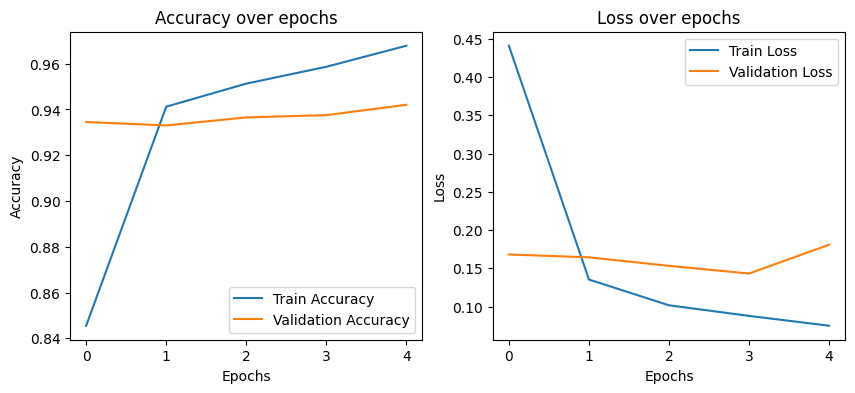

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [ ]:
# Cell 14: View the model summary
model.summary()


Model: "tf_distil_bert_for_sequence_classification_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 distilbert (TFDistilBertMa  multiple                  66362880  
 inLayer)                                                        
                                                                 
 pre_classifier (Dense)      multiple                  590592    
                                                                 
 classifier (Dense)          multiple                  4614      
                                                                 
 dropout_39 (Dropout)        multiple                  0         
                                                                 
Total params: 66958086 (255.42 MB)
Trainable params: 66958086 (255.42 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support


In [ ]:
# Assuming 'test_encodings' and 'test_data' are already prepared and available

test_dataset = tf.data.Dataset.from_tensor_slices((dict(test_encodings), test_data['label'])).batch(32)


In [ ]:
# Get predictions for the test set
y_pred = model.predict(test_dataset)
y_pred_labels = np.argmax(y_pred.logits, axis=1)

# True labels
y_true = test_data['label'].values


63/63 [==============================] - 8s 76ms/step


In [ ]:
# Calculate metrics
report = classification_report(y_true, y_pred_labels, target_names=label_encoder.classes_)

print("Classification Report:")
print(report)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred_labels)
print("Accuracy:", accuracy)

# Other metrics such as F1, Precision, Recall
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred_labels, average='weighted')
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


Classification Report:
              precision    recall  f1-score   support

       anger       0.92      0.94      0.93       275
        fear       0.89      0.94      0.92       224
         joy       0.95      0.94      0.94       695
        love       0.81      0.80      0.80       159
     sadness       0.97      0.97      0.97       581
    surprise       0.81      0.76      0.78        66

    accuracy                           0.93      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.93      0.93      0.93      2000

Accuracy: 0.9295
Precision: 0.9294483240321632
Recall: 0.9295
F1 Score: 0.9293715884958995


In [ ]:
import pandas as pd

# Creating a DataFrame for pretty display
metrics_df = pd.DataFrame({
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1 Score": [f1]
})

print("Metrics Summary:")
print(metrics_df)


Metrics Summary:
   Accuracy  Precision  Recall  F1 Score
0    0.9295   0.929448  0.9295  0.929372


In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns  # For better visualization of confusion matrices


In [ ]:
# Assuming y_pred_labels and y_true are defined from previous steps

# Compute the confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_labels)


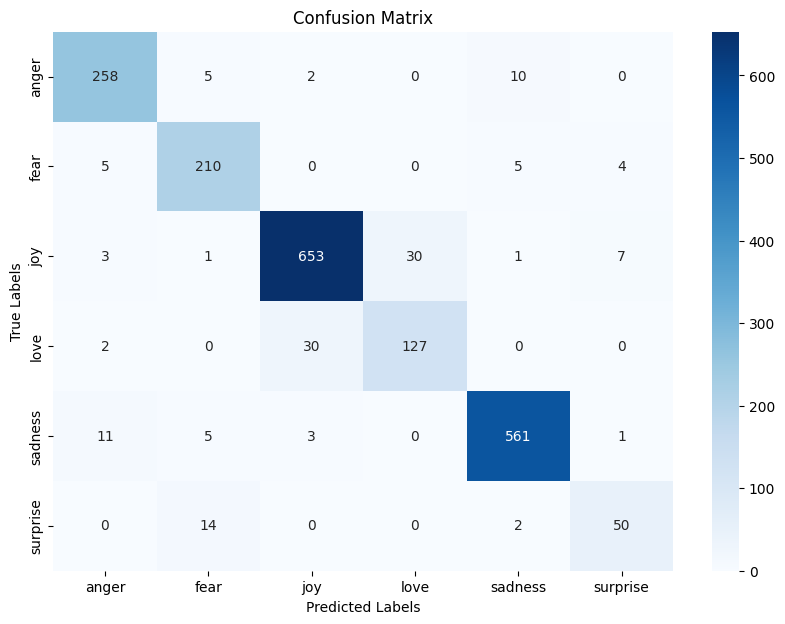

In [ ]:
# Define labels if necessary; adjust according to your dataset
labels = label_encoder.classes_

# Plotting the confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()
